
Formula for ELBO:
    \begin{aligned}L(\phi ,\theta ;x)=&\mathbb {E} _{z\sim q_{\phi }(\cdot |x)}\left[\ln {}p_{\theta }(x,z)\right]+H[q_{\phi }(z|x)]= {\ln } {}\,p_{\theta }(x)-D_{KL}(q_{\phi }(z|x)||p_{\theta }(z|x)).\\\end{aligned}

    Why do we use this formula?
     In a perfect world, we want to maximize the probability of our real data $P(x)$. However, calculating the exact probability across all possible variations of data in a high-dimensional space is mathematically impossible. So, instead of maximizing $P(x)$ directly, we maximize a "lower bound" of it. If we push the lower bound up, $P(x)$ goes up with it.

## Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
import seaborn as sns

# local imports
from model import VAE, VAESupervised, Generator, Discriminator, DiscriminatorNoSigmoid, GeneratorSupervised, DiscriminatorSupervised
from train import vae_loss_function, train_gan, train_gan_grl, train_gan_supervised
from modules import plot_latent_space, plot_manifold, plot_supervised_manifold, plot_gan_manifold, plot_supervised_manifold_gan

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Generative Model of the Variational AutoEncoder


In [3]:
transform = transforms.ToTensor()
mnist_train = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(mnist_train, batch_size=128, shuffle=True)

In [4]:
model_vae = VAE(input_dim=784, hidden_dim=400, latent_dim=2)
optimizer = torch.optim.Adam(model_vae.parameters(), lr=1e-3)

epochs = 15
for epoch in range(epochs):
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = model_vae(data)
        loss = vae_loss_function(recon_batch, data, mu, logvar, 784)
        loss.backward()
        train_loss += loss.item()
        optimizer.step()

    print(f"Epoch: {epoch+1:02d}, loss: {train_loss / len(train_loader.dataset):.4f}")
        

Epoch: 01, loss: 188.0955
Epoch: 02, loss: 166.2248
Epoch: 03, loss: 162.0601
Epoch: 04, loss: 159.6658
Epoch: 05, loss: 157.9746
Epoch: 06, loss: 156.5901
Epoch: 07, loss: 155.5809
Epoch: 08, loss: 154.5576
Epoch: 09, loss: 153.7146
Epoch: 10, loss: 152.9916
Epoch: 11, loss: 152.4443
Epoch: 12, loss: 151.8402
Epoch: 13, loss: 151.3798
Epoch: 14, loss: 150.9295
Epoch: 15, loss: 150.5852


### b. Plot the distribution of the latent vectors using different colors for each digit.

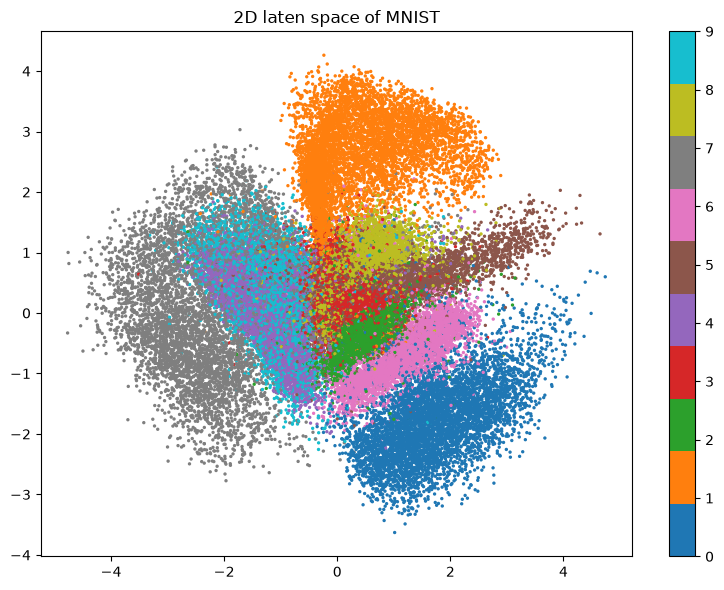

In [5]:
plot_latent_space(model_vae, train_loader)

#### 15x15 mesh in the 2-dimensional latent space.

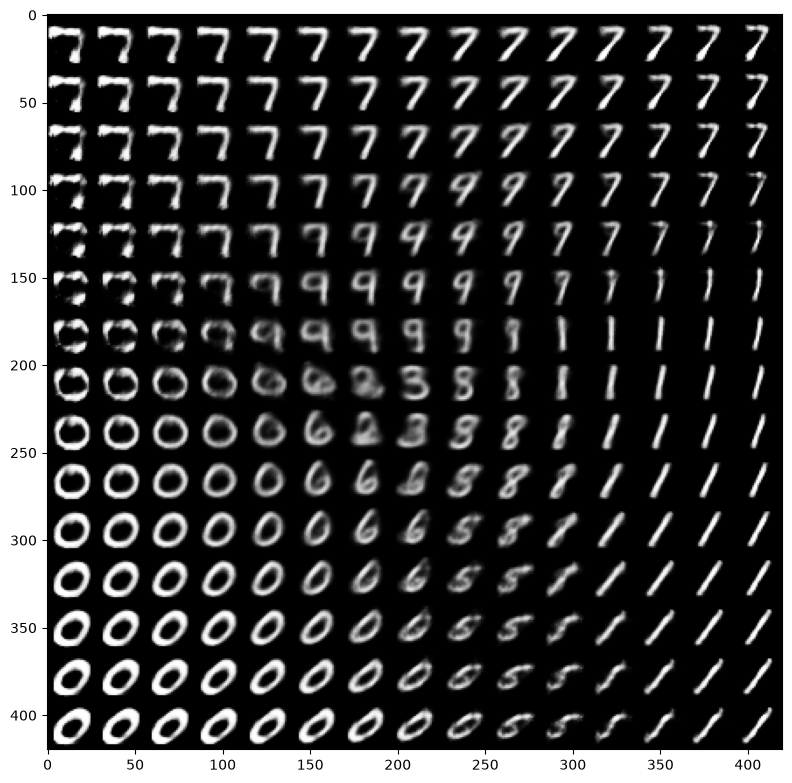

In [6]:
plot_manifold(model_vae)

I could say the model has done its job at least, it was able to successfully diffirenciate digits and capture their positions in the latent space. With that we can see in the first plot, every number has its own "zone" in the latent space. But around the middle of the space it's bit mixed up with little bit of all the numbers, that's where I think the most curcial component of every digit is stored,such as the bare definition of what digit is, we can see it very clearly in the second plot, 15x15 mesh. In the second plot we see that every number is spreaded across the space in their own "zone" again. It's very much like the first plot, but in action.

## Supervised Generative Model of VAE

In [7]:
model_vae_supervised = VAESupervised(input_dim=784, hidden_dim=400, latent_dim=1)
optimizer = torch.optim.Adam(model_vae_supervised.parameters(), lr=1e-3)

epochs = 15
for epoch in range(epochs):
    train_loss = 0
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        # decoder input consists of latent vector and digit label (as a single hot vector).
        digit_labels = F.one_hot(labels, num_classes=10).float().to(device)
        
        optimizer.zero_grad()
        recon_batch, mu, logvar = model_vae_supervised(data, digit_labels)
        loss = vae_loss_function(recon_batch, data, mu, logvar, 784)
        loss.backward()
        train_loss += loss.item()
        optimizer.step()

    print(f"Epoch: {epoch+1:02d}, loss: {train_loss / len(train_loader.dataset):.4f}")

Epoch: 01, loss: 183.9336
Epoch: 02, loss: 156.3723
Epoch: 03, loss: 152.7481
Epoch: 04, loss: 150.6713
Epoch: 05, loss: 149.5633
Epoch: 06, loss: 148.8584
Epoch: 07, loss: 148.3683
Epoch: 08, loss: 147.9955
Epoch: 09, loss: 147.6766
Epoch: 10, loss: 147.4008
Epoch: 11, loss: 147.1914
Epoch: 12, loss: 146.9289
Epoch: 13, loss: 146.7596
Epoch: 14, loss: 146.5797
Epoch: 15, loss: 146.4175


#### 

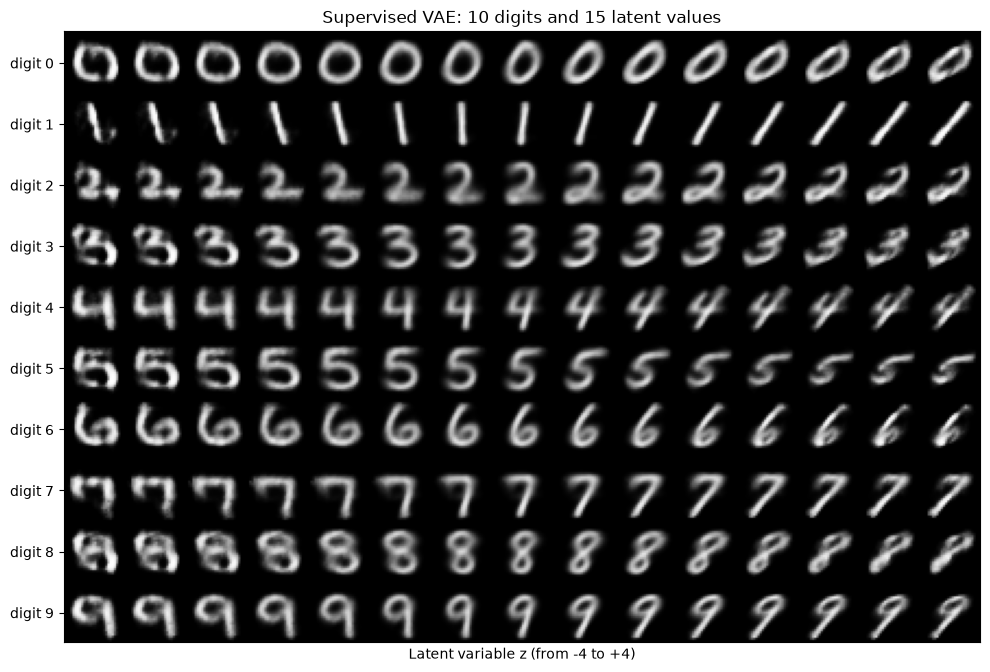

In [8]:
plot_supervised_manifold(model_vae_supervised)

Here it's a bit different, since we have only 1 dimensional latent space it cannot store a lot of information. The identity of the latent space is completely determined by our one-hot encoded labels. The latent space mostly stores information about the overal structure of how a digit should look like, for example the thickness, the height, and such, like the handwriting style. You  can even see it by just comparing different digits from a single row, they are all written in very very similar style. 

## Generative Adversarial Network

In [9]:
netG = Generator().to(device)
netD = Discriminator().to(device)

criterion = nn.BCELoss()
optD = torch.optim.Adam(netD.parameters(), lr=0.0002)
optG = torch.optim.Adam(netG.parameters(), lr=0.0002)

In [10]:
lossD, lossG = train_gan(netG, netD, train_loader, criterion, optG, optD, 15)

#### Loss progress for both generator and discriminator.

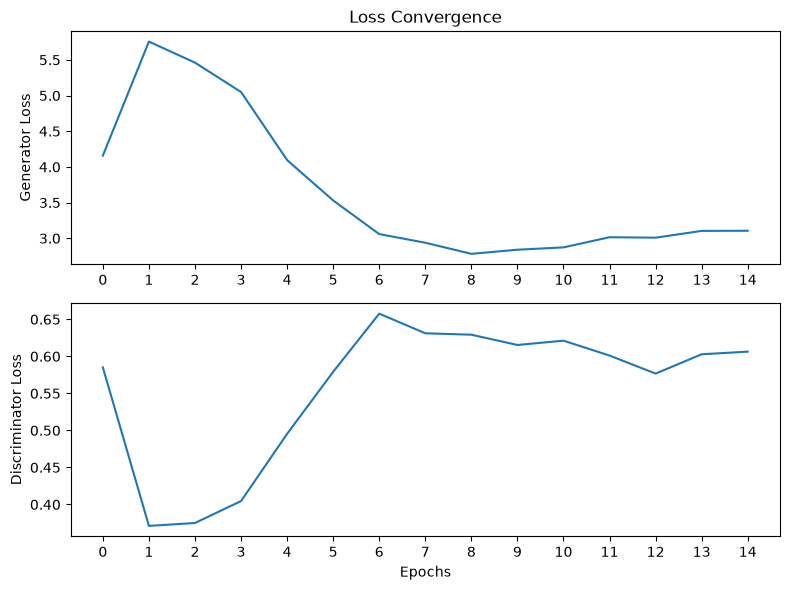

In [11]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize = (8, 6))

ax[0].set_title("Loss Convergence")
ax[0].plot(range(15), lossG)
ax[0].set_ylabel("Generator Loss")
ax[0].set_xticks(range(15))

ax[1].plot(range(15), lossD)
ax[1].set_ylabel("Discriminator Loss")
ax[1].set_xticks(range(15))
ax[1].set_xlabel("Epochs")

plt.tight_layout()
plt.show()

Seems Discriminator has the lead, because:

    the Discriminators job is easy and usually it can learn to diffirentiate between real and fake images really fast, which in this specific case it learned to do so in just one epoch. To prevent that while keeping the Discriminator affective, I softened the true(1) labels by *0.9 so it would be less confident, and currently it did help but not significantly. It may seem that the Discriminator's loss is getting bigger by every epoch, it's because that softened labels ofc. But still it's significantly smaller than the Generators loss. Generator has the harder job, it's not as simple as binary classification, that's why it can't catch up with Discriminator unless we hinder the Discriminator from updating its parameters, and actually, it's a known issue in GANs. And how does Discriminator get's too good at diffirentiating affect the Generator? If the Discriminator get's too good and stops learning it'll cause vanishing gradients problem, so that the Generator can't learn anything new. That's the case we are seeing in this situation.

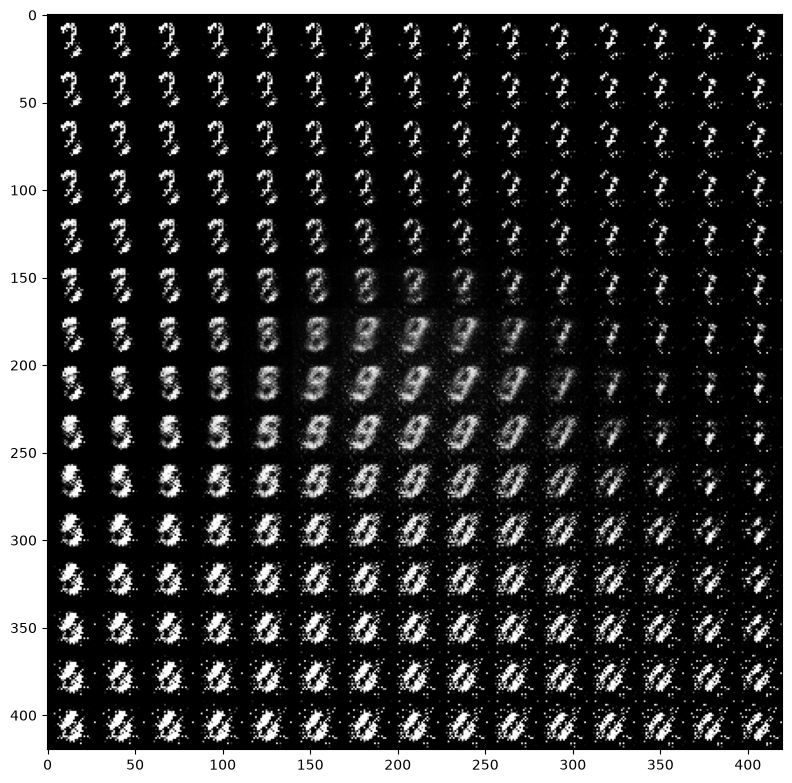

In [12]:
plot_gan_manifold(netG)

From the plot I can say that the Generator needs bigger latent space so that it can generate more accurate images. The ones it generated on the plot is pretty bad, compared to VAE we trained. GANs are really good, but they are also very tricky to train.

## Gradient Reversal
    Normal GAN model consist of two models: Generator and Discriminator, which are doign their best to fool each other in short. The Generator generates a fake image, and the Discriminator has to diffirenciate it from an original image. If the Discriminator has to minimize its loss for predicting the probability of being the original image. Which in turn, Generator has to maximize the Discriminators loss. That's why we can't calculate the same loss for both of them. But using GRL we can do just that, by reversing the signs of Discriminator's greadients and passing it to Generator and then if we calculate Generators loss it'll end up maximizing the Discriminators loss. Why is it usefull? Becuase since now we have a single chain of gradients we don't have to calculate different losses which cuts extra computation. So one single backward trains both.


In [13]:
netG = Generator().to(device)
netD = Discriminator().to(device)

criterion = nn.BCELoss()
optD = torch.optim.Adam(netD.parameters(), lr=0.0002)
optG = torch.optim.Adam(netG.parameters(), lr=0.0002)

In [14]:
loss_grl = train_gan_grl(netG, netD, train_loader, criterion, optG, optD, 15, alpha=0.05, gclip=True)

Epoch [01/15] | Loss: 0.4266
Epoch [02/15] | Loss: 0.3313
Epoch [03/15] | Loss: 0.3422
Epoch [04/15] | Loss: 0.3265
Epoch [05/15] | Loss: 0.3254
Epoch [06/15] | Loss: 0.3252
Epoch [07/15] | Loss: 0.3251
Epoch [08/15] | Loss: 0.3251
Epoch [09/15] | Loss: 0.3251
Epoch [10/15] | Loss: 0.3251
Epoch [11/15] | Loss: 0.3251
Epoch [12/15] | Loss: 0.3251
Epoch [13/15] | Loss: 0.3275
Epoch [14/15] | Loss: 0.3487
Epoch [15/15] | Loss: 0.3252


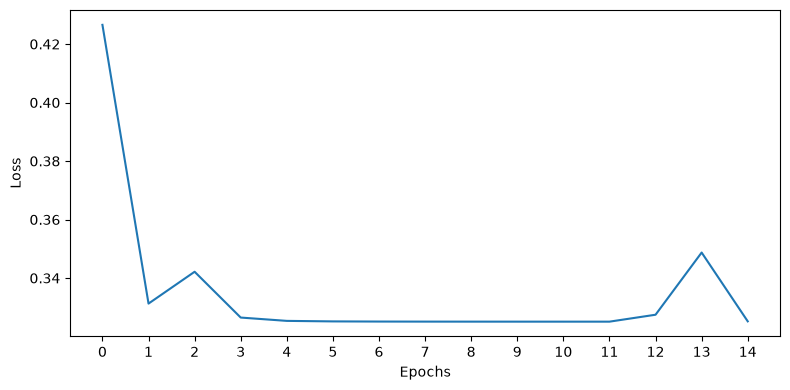

In [15]:
plt.figure(figsize=(8, 4))

plt.plot(range(15), loss_grl)
plt.ylabel("Loss")
plt.xticks(range(15))
plt.xlabel("Epochs")

plt.tight_layout()
plt.show()

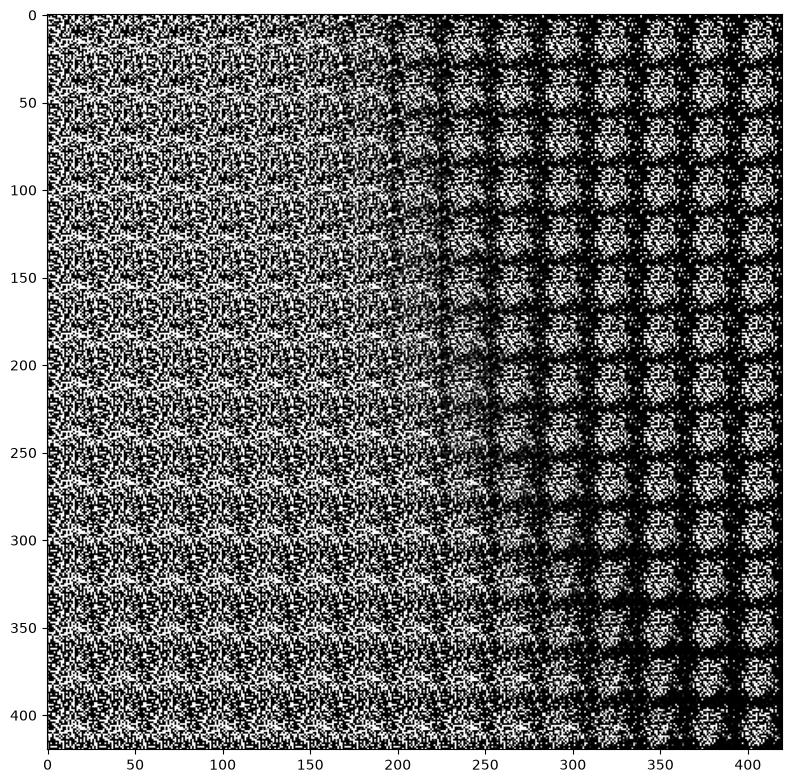

In [16]:
plot_gan_manifold(netG)

<h4>We couldn't achieve anything similar to a normal GAN model with 2 different losses.</h4><br>
Why tho? As I noted above the Discriminator model learns to diffirenciate fake and real images really quickly, resulting in decreasing the gradions. So this in this sitation the Generator model totally depends on how the Discriminator acts. If the Discriminator models learns too quickly and stops learning, the same happens for the Generator model but since it doesn't learn to generate images that fast it'll get stuck with vanishing gradients problem.

## Supervised Generative Adversarial Network

In [17]:
netG = GeneratorSupervised().to(device)
netD = DiscriminatorSupervised().to(device)

criterion = nn.BCELoss()
optD = torch.optim.Adam(netD.parameters(), lr=0.0002)
optG = torch.optim.Adam(netG.parameters(), lr=0.0002)

In [ ]:
lossD, lossG = train_gan_supervised(netG, netD, train_loader, criterion, optG, optD, 15)

In [ ]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize = (7, 5))

ax[0].set_title("Loss Convergence")
ax[0].plot(range(15), lossG)
ax[0].set_ylabel("Supervised Generator Loss")
ax[0].set_xticks(range(15))

ax[1].plot(range(15), lossD)
ax[1].set_ylabel("Discriminator Loss")
ax[1].set_xticks(range(15))
ax[1].set_xlabel("Epochs")
plt.tight_layout()
plt.show()

In [ ]:
plot_supervised_manifold_gan(netG)

- It's much worse compared to supervised VAE model but still, better or worse the model still learned how to draw a digit. And maybe if we could optimize it more it could probably achieve better results.